# PA44 | Predicting outdoor heat-stress events in weather streams
**Data Stream Mining — Final Project, adapted from Practical Assignment I | Portimão (City A) and Covilhã (City B)**

**Student A:** Diogo Caldeirinha — 20231689  
**Student B:** Arsenii Prorokov — 20230784  
**Business setting:** Outdoor Workforce Scheduling Service  
**Assigned event:** T2 — Heat Stress Event  
**Historical archive:** Open-Meteo ERA5, hourly, 2016–2025

We use a common chronological protocol to characterise both city streams, and compare seven incremental classifiers under two feature representations. An eighth learner, **Tuned Online Bagging**, adds the best configuration found by the leakage-safe hyperparameter search (`src/tune_hyperparameters.py`, `results/tuning/FINDINGS.md`).

**Final project extension (FP-T02).** Sections 6–7 add UnimPA and UnimSafe to the PA44 replay and inspect their evolving rules.

**Final project team:** Diogo Caldeirinha, Arsenii Prorokov, Vladislav Botnev, Victoriya Mokhovikova and Yan Sidoryk.

## 1. Business context and experimental choices
Our assigned question is: **Which location presents fewer high-temperature stress periods for outdoor workers?** Weather alone can inform this operational dimension; it cannot determine overall business suitability.

We define an illustrative shift as **Monday–Friday, 08:00–18:00 Europe/Lisbon time** (no holiday exclusions).

## 2. Data and stream construction
### 2.1 Environment, project folders and data retrieval
We collect four hourly ERA5 variables: temperature (°C), relative humidity (%), precipitation (mm) and 10-m wind speed (km/h). We cache the unaltered API responses in `data/raw/` so repeated runs reuse the same snapshots. All stream operations use **UTC** timestamps; the work-shift calendar uses **Europe/Lisbon** local time, including daylight-saving transitions.

In [1]:
from __future__ import annotations

import importlib.metadata as metadata
import json
import platform
import sys
import time
from collections import deque
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from requests.adapters import HTTPAdapter
from sklearn.preprocessing import StandardScaler
from urllib3.util.retry import Retry

# Resolve the project root whether Jupyter starts in the root or in src/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'src':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise RuntimeError('Open the notebook inside the provided PA44 project folder.')

RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
RESULTS_DIR = PROJECT_ROOT / 'results'
TABLES_DIR = RESULTS_DIR / 'tables'
FIGURES_DIR = RESULTS_DIR / 'figures'
for directory in (RAW_DIR, PROCESSED_DIR, RESULTS_DIR, TABLES_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

PA_CODE = 'PA44'
CITIES = {
    'Portimão': {'latitude': 37.1366, 'longitude': -8.5377},
    'Covilhã': {'latitude': 40.2806, 'longitude': -7.5039},
}
CITY_A, CITY_B = CITIES
START_DATE, END_DATE = '2016-01-01', '2025-12-31'
WARMUP_END_UTC = pd.Timestamp('2017-12-31 23:00:00', tz='UTC')
LOCAL_TZ = 'Europe/Lisbon'
SHIFT_START, SHIFT_END = 8, 18  # Inclusive start, exclusive end.
RAW_VARIABLES = [
    'temperature_2m', 'relative_humidity_2m',
    'precipitation', 'wind_speed_10m',
]
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'
WEATHER_MODEL = 'era5'
TARGET_QUANTILE = 0.80
RANDOM_SEED = 42
ENSEMBLE_SIZE = 5
ROLLING_SCORE_WINDOW = 300
CHECKPOINT_EVERY = 250
FORCE_DOWNLOAD = False  # Change only to deliberately refresh snapshots.

np.random.seed(RANDOM_SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10})


def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return 'not installed'


def save_figure(filename):
    plt.savefig(FIGURES_DIR / filename, bbox_inches='tight')
    plt.show()
    plt.close()


RUN_CONFIG = {
    'assignment': PA_CODE,
    'cities': list(CITIES),
    'period': [START_DATE, END_DATE],
    'warmup_end_utc': WARMUP_END_UTC.isoformat(),
    'working_hours': 'Mon–Fri, 08:00–17:59 Europe/Lisbon',
    'weather_model': WEATHER_MODEL,
    'target': 'T2 — pooled 2016-2017 warm-up temperature 80th percentile',
    'random_seed': RANDOM_SEED,
    'ensemble_size': ENSEMBLE_SIZE,
    'python_version': platform.python_version(),
    'packages': {p: installed_version(p) for p in (
        'numpy', 'pandas', 'matplotlib', 'requests', 'scikit-learn', 'river')},
    'generated_utc': datetime.now(timezone.utc).isoformat(),
}
(RESULTS_DIR / 'environment.json').write_text(
    json.dumps(RUN_CONFIG, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Project:', PROJECT_ROOT)
print('Python:', RUN_CONFIG['python_version'], '| Random seed:', RANDOM_SEED)

Project: C:\Users\arpro\Documents\NOVA\DataStream\FINAL\data_stream_mining_final
Python: 3.12.12 | Random seed: 42


In [2]:
def fetch_year(city, year):
    """Read a cached unmodified API payload, or download it once."""
    file = RAW_DIR / f'{city.lower().replace("ã", "a").replace("í", "i")}_{year}_{WEATHER_MODEL}.json'
    if file.exists() and not FORCE_DOWNLOAD:
        payload = json.loads(file.read_text(encoding='utf-8'))
        origin = 'cached'
    else:
        location = CITIES[city]
        params = {
            'latitude': location['latitude'], 'longitude': location['longitude'],
            'start_date': f'{year}-01-01', 'end_date': f'{year}-12-31',
            'hourly': ','.join(RAW_VARIABLES), 'models': WEATHER_MODEL,
            'timezone': 'GMT', 'temperature_unit': 'celsius',
            'wind_speed_unit': 'kmh', 'precipitation_unit': 'mm',
        }
        retry = Retry(total=4, backoff_factor=1.5,
                      status_forcelist=[429, 500, 502, 503, 504])
        with requests.Session() as session:
            session.mount('https://', HTTPAdapter(max_retries=retry))
            try:
                response = session.get(ARCHIVE_URL, params=params, timeout=(15, 120))
                response.raise_for_status()
                payload = response.json()
            except requests.RequestException as error:
                raise RuntimeError(f'Cannot retrieve {city}, {year}: {error}') from error
        if payload.get('error'):
            raise RuntimeError(f'Open-Meteo error for {city}: {payload.get("reason")}')
        file.write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')
        origin = 'downloaded'

    hourly = payload.get('hourly', {})
    if 'time' not in hourly or any(column not in hourly for column in RAW_VARIABLES):
        raise ValueError(f'Unexpected API fields in {file.name}')
    n = len(hourly['time'])
    if any(len(hourly[column]) != n for column in RAW_VARIABLES):
        raise ValueError(f'Inconsistent hourly array lengths in {file.name}')
    return payload, {'city': city, 'year': year, 'file': file.name,
                     'source': origin, 'hours_received': n}


def payload_to_frame(payload, city):
    """Parse GMT timestamps as UTC; never discard missing hours."""
    hourly = payload['hourly']
    timestamps = pd.DatetimeIndex(pd.to_datetime(hourly['time'], utc=True),
                                  name='timestamp_utc')
    if timestamps.has_duplicates:
        raise ValueError(f'{city}: duplicate timestamps in an API response')
    values = {name: pd.to_numeric(pd.Series(hourly[name]), errors='coerce').to_numpy()
              for name in RAW_VARIABLES}
    return pd.DataFrame(values, index=timestamps).sort_index()


def load_weather(city):
    yearly_frames = []
    for year in range(2016, 2026):
        payload, record = fetch_year(city, year)
        retrieval_log.append(record)
        yearly_frames.append(payload_to_frame(payload, city))
    frame = pd.concat(yearly_frames).sort_index()
    if frame.index.has_duplicates:
        raise ValueError(f'{city}: duplicate timestamps across yearly snapshots')
    expected = pd.date_range('2016-01-01 00:00', '2025-12-31 23:00',
                             freq='h', tz='UTC', name='timestamp_utc')
    if not frame.index.difference(expected).empty:
        raise ValueError(f'{city}: unexpected dates outside the chosen period')
    return frame.reindex(expected)  # Gaps become missing values, not hidden deletions.


retrieval_log = []
weather = {city: load_weather(city) for city in CITIES}
pd.DataFrame(retrieval_log).to_csv(PROCESSED_DIR / 'source_manifest.csv', index=False)
assert weather[CITY_A].index.equals(weather[CITY_B].index)
print('Loaded shared UTC calendar:', len(weather[CITY_A]), 'hourly timestamps')

Loaded shared UTC calendar: 87672 hourly timestamps


### 2.2 Quality assessment and stream integrity
We count missing values, check basic physical-domain constraints and flag unusually extreme observations for review. **We never remove extremes automatically.** Missing timestamps remain explicit. If clearly invalid values are encountered, execution stops for documented investigation rather than silently altering the stream.

In [3]:
def quality_audit(data):
    rows = []
    for city, frame in data.items():
        for variable in RAW_VARIABLES:
            values = frame[variable]
            observed = values.dropna()
            q1, q3 = observed.quantile([0.25, 0.75])
            iqr = q3 - q1
            broad_extremes = ((observed < q1 - 3 * iqr) |
                              (observed > q3 + 3 * iqr)).sum()
            invalid = ~np.isfinite(observed.to_numpy(dtype=float))
            if variable == 'relative_humidity_2m':
                invalid |= ((observed < 0) | (observed > 100)).to_numpy()
            elif variable in ('precipitation', 'wind_speed_10m'):
                invalid |= (observed < 0).to_numpy()
            elif variable == 'temperature_2m':
                invalid |= ((observed < -90) | (observed > 70)).to_numpy()
            rows.append({
                'city': city, 'variable': variable,
                'calendar_hours': len(frame), 'missing_n': int(values.isna().sum()),
                'missing_pct': 100 * float(values.isna().mean()),
                'min': observed.min(), 'median': observed.median(),
                'max': observed.max(), 'wide_iqr_review_flags': int(broad_extremes),
                'invalid_domain_n': int(invalid.sum()),
            })
    return pd.DataFrame(rows)


quality = quality_audit(weather)
display(quality.round(2))
quality.to_csv(TABLES_DIR / 'data_quality.csv', index=False)
if quality['invalid_domain_n'].sum() > 0:
    raise RuntimeError('Invalid physical-domain values found. Investigate raw snapshots '
                       'and document a correction before running the analysis.')
print('Wide-IQR flags are descriptive review flags, not automatic deletion rules.')

,city,variable,calendar_hours,missing_n,missing_pct,min,median,max,wide_iqr_review_flags,invalid_domain_n
0,Portimão,temperature_2m,87672,0,0.0,-0.9,17.6,44.3,0,0
1,Portimão,relative_humidity_2m,87672,0,0.0,10.0,74.0,100.0,0,0
2,Portimão,precipitation,87672,0,0.0,0.0,0.0,9.3,7567,0
3,Portimão,wind_speed_10m,87672,0,0.0,0.0,11.8,51.9,2,0
4,Covilhã,temperature_2m,87672,0,0.0,-4.1,13.1,39.4,0,0
5,Covilhã,relative_humidity_2m,87672,0,0.0,8.0,74.0,100.0,0,0
6,Covilhã,precipitation,87672,0,0.0,0.0,0.0,11.3,14612,0
7,Covilhã,wind_speed_10m,87672,0,0.0,0.0,8.0,33.5,123,0


Wide-IQR flags are descriptive review flags, not automatic deletion rules.


### 2.3 Fixed pooled warm-up threshold and leakage-free predictors
We build the work-hour calendar **before inspecting target values**. The warm-up ends on 31 December 2017. We calculate one shared 80th-percentile threshold from all observed **eligible work-hour temperatures in 2016–2017**, using both cities. The current temperature then defines the label but does not appear in any feature representation.

Representation A and B are constructed from the uninterrupted hourly weather archive before we filter to scheduled work hours; overnight and weekend weather therefore remains available as past context. Missing predictor values are handled **later**, using medians fitted only to warm-up records.

In [4]:
REP_A = [f'lag1_{variable}' for variable in RAW_VARIABLES]
REP_B = REP_A + [
    'temperature_change_1h',
    'temperature_mean_6h',
    'temperature_std_6h',
    'humidity_mean_6h',
    'rainy_hours_24h',
    'shift_hour_sin',
    'shift_hour_cos',
]
assert len(REP_A) == 4 and len(REP_B) == 11
assert 'temperature_2m' not in REP_A + REP_B
assert len(set(REP_B)) == len(REP_B)


def shift_mask(timestamps):
    local = timestamps.tz_convert(LOCAL_TZ)
    return (local.weekday < 5) & (local.hour >= SHIFT_START) & (local.hour < SHIFT_END)


# Fix the boundary using the calendar, not a data-dependent count of valid labels.
calendar = weather[CITY_A].index
eligible_calendar = calendar[shift_mask(calendar)]
warm_calendar = eligible_calendar[eligible_calendar <= WARMUP_END_UTC]
eval_calendar = eligible_calendar[eligible_calendar > WARMUP_END_UTC]

warm_temperatures = pd.concat(
    [weather[city].loc[warm_calendar, 'temperature_2m'].dropna() for city in CITIES],
    ignore_index=True,
)
if len(warm_temperatures) < 100:
    raise RuntimeError('Too few pooled observed warm-up temperatures.')
HOT_THRESHOLD_C = float(warm_temperatures.quantile(TARGET_QUANTILE))


def construct_stream(frame, threshold):
    """Build a target at t and predictors from data available strictly before t."""
    out = pd.DataFrame(index=frame.index)
    local = frame.index.tz_convert(LOCAL_TZ)
    out['local_date'] = local.date
    out['local_month'] = local.month
    out['local_hour'] = local.hour
    out['eligible_shift'] = shift_mask(frame.index)

    temperature = frame['temperature_2m']
    target = (temperature >= threshold).astype('Int64')
    out['y_event'] = target.where(temperature.notna(), pd.NA)

    # shift(1) means the latest weather information is at t-1.
    for variable in RAW_VARIABLES:
        out[f'lag1_{variable}'] = frame[variable].shift(1)
    earlier_temperature = temperature.shift(1)
    out['temperature_change_1h'] = temperature.shift(1) - temperature.shift(2)
    out['temperature_mean_6h'] = earlier_temperature.rolling(6, min_periods=4).mean()
    out['temperature_std_6h'] = earlier_temperature.rolling(6, min_periods=4).std(ddof=0)
    out['humidity_mean_6h'] = frame['relative_humidity_2m'].shift(1).rolling(
        6, min_periods=4).mean()
    observed_rain = (frame['precipitation'] >= 0.1).astype(float)
    observed_rain = observed_rain.where(frame['precipitation'].notna(), np.nan)
    out['rainy_hours_24h'] = observed_rain.shift(1).rolling(24, min_periods=18).sum()

    # Calendar features are known before the target hour begins.
    out['shift_hour_sin'] = np.sin(2 * np.pi * local.hour / 24)
    out['shift_hour_cos'] = np.cos(2 * np.pi * local.hour / 24)
    return out


stream_full = {city: construct_stream(frame, HOT_THRESHOLD_C)
               for city, frame in weather.items()}
threshold_record = {
    'quantile': TARGET_QUANTILE, 'threshold_celsius': HOT_THRESHOLD_C,
    'warmup_first_utc': str(warm_calendar.min()),
    'warmup_last_utc': str(warm_calendar.max()),
    'pooled_observed_warmup_hours': int(len(warm_temperatures)),
    'warmup_city_counts': {city: int(weather[city].loc[warm_calendar, 'temperature_2m'].count())
                           for city in CITIES},
}
(RESULTS_DIR / 'target_definition.json').write_text(
    json.dumps(threshold_record, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Frozen T2 threshold: {HOT_THRESHOLD_C:.3f} °C '
      f'(pooled 2016-2017 work-hour 80th percentile; n={len(warm_temperatures):,}).')

Frozen T2 threshold: 26.100 °C (pooled 2016-2017 work-hour 80th percentile; n=10,420).


In [5]:
# Synthetic alignment test: modifying current or future weather cannot modify X_t.
fixture_times = pd.date_range('2024-06-01', periods=100, freq='h', tz='UTC')
fixture = pd.DataFrame({
    'temperature_2m': 20 + np.sin(np.arange(100) / 6),
    'relative_humidity_2m': 55 + np.cos(np.arange(100) / 5),
    'precipitation': np.zeros(100),
    'wind_speed_10m': np.full(100, 7.0),
}, index=fixture_times)
original = construct_stream(fixture, 20.5)
modified_fixture = fixture.copy()
modified_fixture.loc[fixture_times[70], 'temperature_2m'] = 65.0
modified = construct_stream(modified_fixture, 20.5)
pd.testing.assert_series_equal(
    original.loc[fixture_times[70], REP_B], modified.loc[fixture_times[70], REP_B]
)
assert original.loc[fixture_times[70], 'y_event'] != modified.loc[fixture_times[70], 'y_event']
assert original.loc[fixture_times[70], 'lag1_temperature_2m'] == fixture.loc[
    fixture_times[69], 'temperature_2m']
print('PASS — changing temperature(t) changes the label, not predictors X(t).')

PASS — changing temperature(t) changes the label, not predictors X(t).

### 2.4 Common replay cohort and frozen preprocessing
We score only hours where **both cities have an observed current-hour temperature**; therefore every city and model receives the same chronological evaluation timestamps. We report excluded hours in the audit table. Within this cohort, we fit missing-feature medians and a standard scaler on the pooled **2016–2017 warm-up only**, then reuse these frozen values during 2018–2025. No missing target is imputed.

In [6]:
# Cohort membership is determined from the work calendar and observed labels.
labeled_by_city = {
    city: stream_full[city].loc[eligible_calendar, 'y_event'].notna()
    for city in CITIES
}
paired_valid = labeled_by_city[CITY_A] & labeled_by_city[CITY_B]
model_times = eligible_calendar[paired_valid.to_numpy()]
warm_times = model_times[model_times <= WARMUP_END_UTC]
eval_times = model_times[model_times > WARMUP_END_UTC]
if len(warm_times) < 100 or len(eval_times) < 100:
    raise RuntimeError('Not enough paired labeled work hours for a valid experiment.')
assert warm_times.is_monotonic_increasing and eval_times.is_monotonic_increasing
assert warm_times.max() < eval_times.min()

cohort = pd.DataFrame([{
    'city': city,
    'scheduled_calendar_hours': len(eligible_calendar),
    'warmup_scheduled_hours': len(warm_calendar),
    'evaluation_scheduled_hours': len(eval_calendar),
    'city_missing_target_hours': int((~labeled_by_city[city]).sum()),
    'paired_warmup_hours': len(warm_times),
    'paired_evaluation_hours': len(eval_times),
    'paired_excluded_hours': len(eligible_calendar) - len(model_times),
} for city in CITIES])
cohort.to_csv(TABLES_DIR / 'cohort_audit.csv', index=False)
display(cohort)

# Descriptive class balance for both phases (not used to fit a threshold or tune a model).
class_rows = []
for city in CITIES:
    for phase, timestamps in (('warmup', warm_times), ('evaluation', eval_times)):
        labels = stream_full[city].loc[timestamps, 'y_event'].astype(int)
        event_n = int(labels.sum())
        class_rows.append({
            'city': city, 'phase': phase, 'observed_paired_hours': len(labels),
            'non_event_n': len(labels) - event_n, 'event_n': event_n,
            'event_rate_pct': 100 * event_n / len(labels),
        })
class_distribution = pd.DataFrame(class_rows)
class_distribution.to_csv(TABLES_DIR / 'class_distribution_by_phase.csv', index=False)
display(class_distribution.round(2))

# Median imputation and scaling are learned from the exact pooled warm-up cohort.
pooled_warmup = pd.concat(
    [stream_full[city].loc[warm_times, REP_B] for city in CITIES],
    ignore_index=True,
)
warm_medians = pooled_warmup.median(numeric_only=True)
if warm_medians.isna().any():
    raise RuntimeError('An entire warm-up feature is missing: '
                       + ', '.join(warm_medians.index[warm_medians.isna()]))

feature_audit = []
scaled_inputs = {}
scaler_config = {}
for representation, features in (('A', REP_A), ('B', REP_B)):
    fitted_scaler = StandardScaler().fit(pooled_warmup[features].fillna(warm_medians))
    scaler_config[representation] = {
        'features': features,
        'means': fitted_scaler.mean_.tolist(),
        'scales': fitted_scaler.scale_.tolist(),
    }
    for city in CITIES:
        unscaled = stream_full[city].loc[model_times, features]
        for feature in features:
            feature_audit.append({
                'city': city, 'representation': representation, 'feature': feature,
                'missing_predictor_n': int(unscaled[feature].isna().sum()),
                'pooled_warmup_imputation_median': float(warm_medians[feature]),
            })
        prepared = unscaled.fillna(warm_medians)
        array = fitted_scaler.transform(prepared)
        if not np.isfinite(array).all():
            raise RuntimeError(f'{city}, {representation}: non-finite prepared features')
        scaled_inputs[(city, representation)] = pd.DataFrame(
            array, index=model_times, columns=features,
        )

feature_audit_df = pd.DataFrame(feature_audit)
feature_audit_df.to_csv(TABLES_DIR / 'feature_missingness_imputation.csv', index=False)
(RESULTS_DIR / 'preprocessing.json').write_text(
    json.dumps(scaler_config, indent=2), encoding='utf-8')

for city in CITIES:
    # Store labeled model rows with the unscaled, interpretable features.
    prepared_stream = stream_full[city].loc[model_times, ['y_event', 'eligible_shift'] + REP_B]
    prepared_stream.to_csv(PROCESSED_DIR / f'{"city_A" if city == CITY_A else "city_B"}_model_stream.csv')

print(f'Paired labeled hours: {len(warm_times):,} warm-up, {len(eval_times):,} evaluation.')
print('Predictor imputation and scaling: pooled warm-up statistics only.')

,city,scheduled_calendar_hours,warmup_scheduled_hours,evaluation_scheduled_hours,city_missing_target_hours,paired_warmup_hours,paired_evaluation_hours,paired_excluded_hours
0,Portimão,26090,5210,20880,0,5210,20880,0
1,Covilhã,26090,5210,20880,0,5210,20880,0


,city,phase,observed_paired_hours,non_event_n,event_n,event_rate_pct
0,Portimão,warmup,5210,3855,1355,26.01
1,Portimão,evaluation,20880,16025,4855,23.25
2,Covilhã,warmup,5210,4446,764,14.66
3,Covilhã,evaluation,20880,18177,2703,12.95


Paired labeled hours: 5,210 warm-up, 20,880 evaluation.
Predictor imputation and scaling: pooled warm-up statistics only.


## 3. City A — Portimão
We independently document Portimão’s weather distributions, scheduled-hour event prevalence, monthly evolution and consecutive hot-event episodes. We use **all observed scheduled hours** for descriptive analysis; the separate model cohort is documented above.

C:\Users\arpro\AppData\Local\Temp\ipykernel_23500\436981801.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  run_ids = (hot.index.to_series().diff() != pd.Timedelta(hours=1)).cumsum()


,city,observed_shift_hours,heat_event_n,non_event_n,heat_event_rate_pct,temperature_mean_c,temperature_std_c,temperature_p95_c,temperature_max_c,event_episode_n,longest_episode_hours,mean_episode_hours,shift_days_3plus_events_pct
0,Portimão,26090,6210,19880,23.8,21.0,6.5,32.4,41.3,975,10,6.37,35.22


,mean,std,min,50%,max
variable,,,,,
temperature_2m,18.29,6.46,-0.9,17.6,44.3
relative_humidity_2m,70.08,20.40,10.0,74.0,100.0
precipitation,0.05,0.27,0.0,0.0,9.3
wind_speed_10m,12.76,6.55,0.0,11.8,51.9


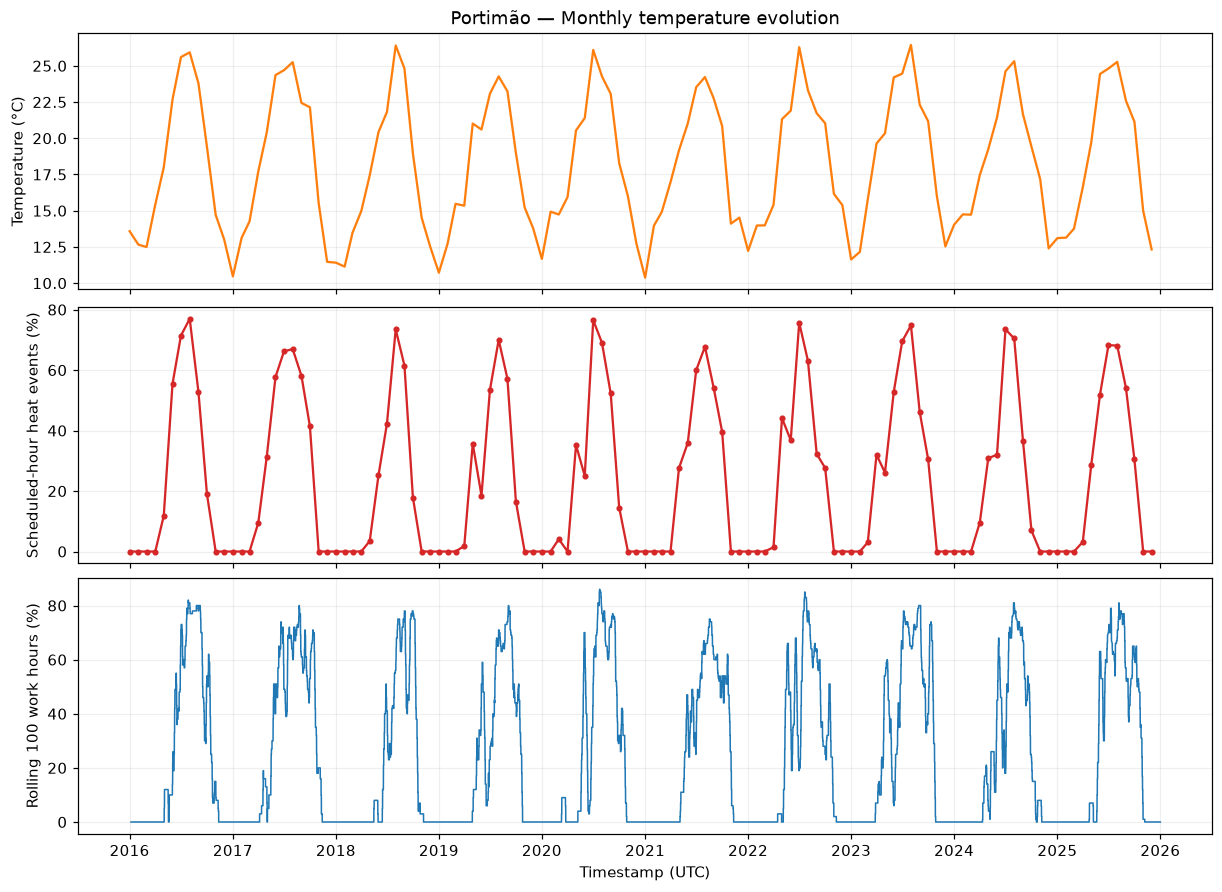

In [7]:
def observed_shift(city):
    stream = stream_full[city]
    return stream.loc[stream['eligible_shift'] & stream['y_event'].notna()].copy()


def consecutive_hot_episodes(work_hours):
    """Count contiguous one-hour hot-event runs; overnight gaps end a run."""
    hot = work_hours.loc[work_hours['y_event'].eq(1)]
    if hot.empty:
        return pd.Series(dtype='int64', name='hours')
    run_ids = (hot.index.to_series().diff() != pd.Timedelta(hours=1)).cumsum()
    return hot.groupby(run_ids).size().rename('hours')


def city_statistics(city):
    work = observed_shift(city)
    actual_temperature = weather[city].loc[work.index, 'temperature_2m']
    episodes = consecutive_hot_episodes(work)
    day_counts = work.groupby('local_date')['y_event'].sum()
    row = {
        'city': city, 'observed_shift_hours': len(work),
        'heat_event_n': int(work['y_event'].sum()),
        'non_event_n': int((work['y_event'] == 0).sum()),
        'heat_event_rate_pct': 100 * float(work['y_event'].mean()),
        'temperature_mean_c': actual_temperature.mean(),
        'temperature_std_c': actual_temperature.std(),
        'temperature_p95_c': actual_temperature.quantile(.95),
        'temperature_max_c': actual_temperature.max(),
        'event_episode_n': len(episodes),
        'longest_episode_hours': int(episodes.max()) if len(episodes) else 0,
        'mean_episode_hours': episodes.mean() if len(episodes) else 0.0,
        'shift_days_3plus_events_pct': 100 * day_counts.ge(3).mean(),
    }
    monthly = work.groupby(pd.Grouper(freq='MS')).agg(
        observed_hours=('y_event', 'size'),
        event_hours=('y_event', 'sum'),
    )
    monthly['event_rate_pct'] = 100 * monthly['event_hours'] / monthly['observed_hours']
    description = weather[city][RAW_VARIABLES].describe().T
    description.index.name = 'variable'
    return row, monthly, description, episodes


def output_city(city, tag):
    stats, monthly, description, episodes = city_statistics(city)
    pd.DataFrame([stats]).to_csv(TABLES_DIR / f'city_{tag}_profile.csv', index=False)
    monthly.to_csv(TABLES_DIR / f'city_{tag}_monthly_events.csv')
    description.to_csv(TABLES_DIR / f'city_{tag}_weather_statistics.csv')
    episodes.to_frame().to_csv(TABLES_DIR / f'city_{tag}_event_episodes.csv', index=False)
    yearly = observed_shift(city).groupby(pd.Grouper(freq='YS'))['y_event'].agg(['size', 'sum'])
    yearly.columns = ['observed_hours', 'event_hours']
    yearly['non_event_hours'] = yearly['observed_hours'] - yearly['event_hours']
    yearly['event_rate_pct'] = 100 * yearly['event_hours'] / yearly['observed_hours']
    yearly.to_csv(TABLES_DIR / f'city_{tag}_yearly_class_distribution.csv')
    display(pd.DataFrame([stats]).round(2))
    display(description[['mean', 'std', 'min', '50%', 'max']].round(2))

    fig, ax = plt.subplots(
    3, 1, figsize=(11, 8),
    sharex=True, layout='constrained'
    )

    # 1. Monthly temperature
    monthly_temperature = weather[city]['temperature_2m'].resample('MS').mean()

    ax[0].plot(
        monthly_temperature.index,
        monthly_temperature.values,
        color='tab:orange'
    )
    ax[0].set(
        title=f'{city} — Monthly temperature evolution',
        ylabel='Temperature (°C)'
    )

    # 2. Monthly heat-event frequency
    ax[1].plot(
        monthly.index,
        monthly['event_rate_pct'].to_numpy(),
        marker='o',
        markersize=3,
        color='tab:red'
    )
    ax[1].set(ylabel='Scheduled-hour heat events (%)')

    # 3. Rolling event frequency
    weekly = (
        observed_shift(city)['y_event']
        .astype(float)
        .rolling(100, min_periods=30)
        .mean()
    )

    ax[2].plot(
        weekly.index,
        100 * weekly.to_numpy(),
        linewidth=1,
        color='tab:blue'
    )
    ax[2].set(
        ylabel='Rolling 100 work hours (%)',
        xlabel='Timestamp (UTC)'
    )

    for axis in ax:
        axis.grid(alpha=0.2)

    save_figure(f'city_{tag}_temporal_profile.png')
    return stats, monthly, episodes


city_a_profile, city_a_monthly, city_a_episodes = output_city(CITY_A, 'A')

## 4. City B — Covilhã
We apply **exactly the same descriptive functions, temporal windows and metrics** to Covilhã. This keeps the city analyses consistent while allowing each student to interpret their primary city independently.

C:\Users\arpro\AppData\Local\Temp\ipykernel_23500\436981801.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  run_ids = (hot.index.to_series().diff() != pd.Timedelta(hours=1)).cumsum()


,city,observed_shift_hours,heat_event_n,non_event_n,heat_event_rate_pct,temperature_mean_c,temperature_std_c,temperature_p95_c,temperature_max_c,event_episode_n,longest_episode_hours,mean_episode_hours,shift_days_3plus_events_pct
0,Covilhã,26090,3467,22623,13.29,16.34,7.65,30.1,39.4,615,10,5.64,21.81


,mean,std,min,50%,max
variable,,,,,
temperature_2m,14.14,7.47,-4.1,13.1,39.4
relative_humidity_2m,70.53,21.96,8.0,74.0,100.0
precipitation,0.11,0.45,0.0,0.0,11.3
wind_speed_10m,8.60,3.91,0.0,8.0,33.5


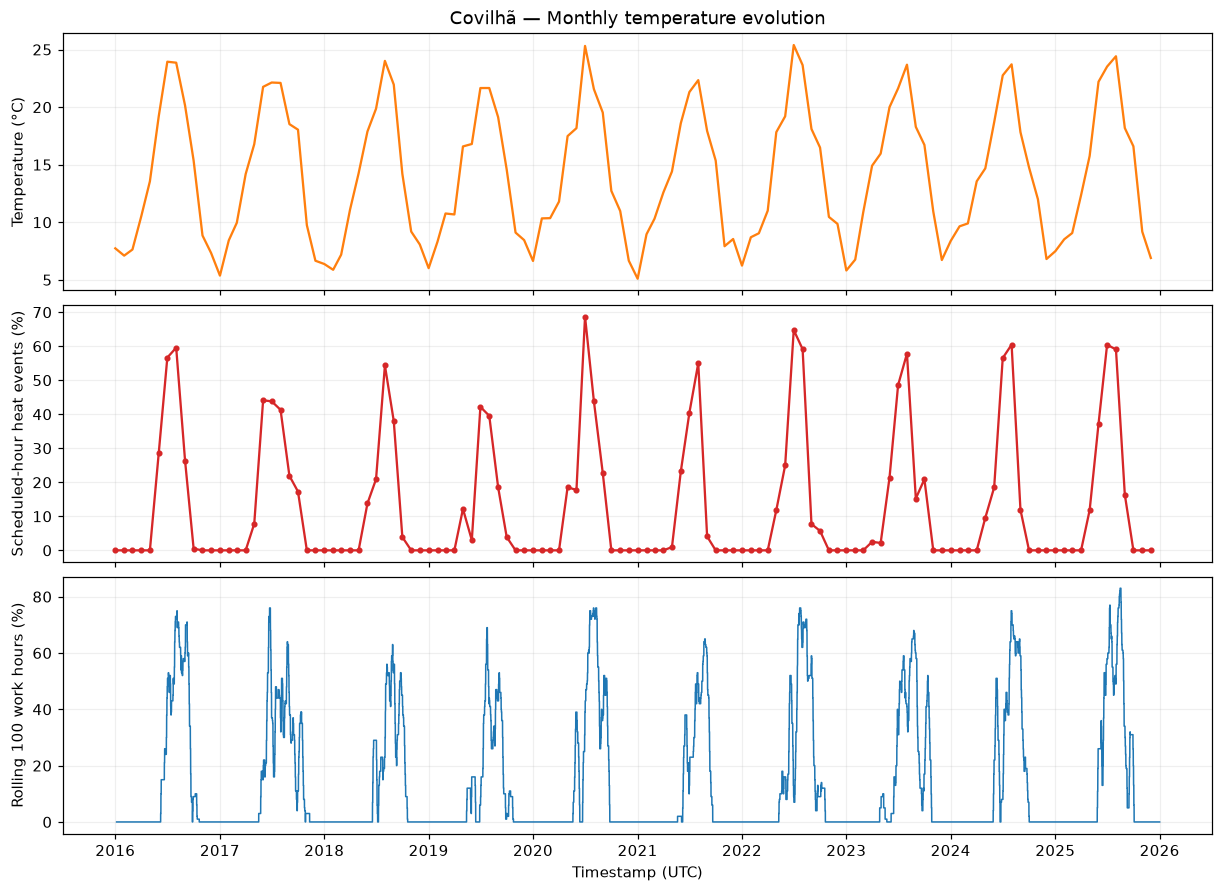

In [8]:
city_b_profile, city_b_monthly, city_b_episodes = output_city(CITY_B, 'B')

## 5. Comparative data analysis (before modelling)
We first compare **event exposure and persistence**, without using predictive accuracy as a proxy for city suitability. Two original visual analyses are provided: **(O1)** the month × shift-hour heat-event calendar and **(O2)** the distribution of consecutive heat-event durations. A shared colour scale and consistent denominators preserve comparability.

,observed_shift_hours,heat_event_n,non_event_n,heat_event_rate_pct,temperature_mean_c,temperature_std_c,temperature_p95_c,temperature_max_c,event_episode_n,longest_episode_hours,mean_episode_hours,shift_days_3plus_events_pct
city,,,,,,,,,,,,
Portimão,26090,6210,19880,23.80,21.00,6.50,32.4,41.3,975,10,6.37,35.22
Covilhã,26090,3467,22623,13.29,16.34,7.65,30.1,39.4,615,10,5.64,21.81


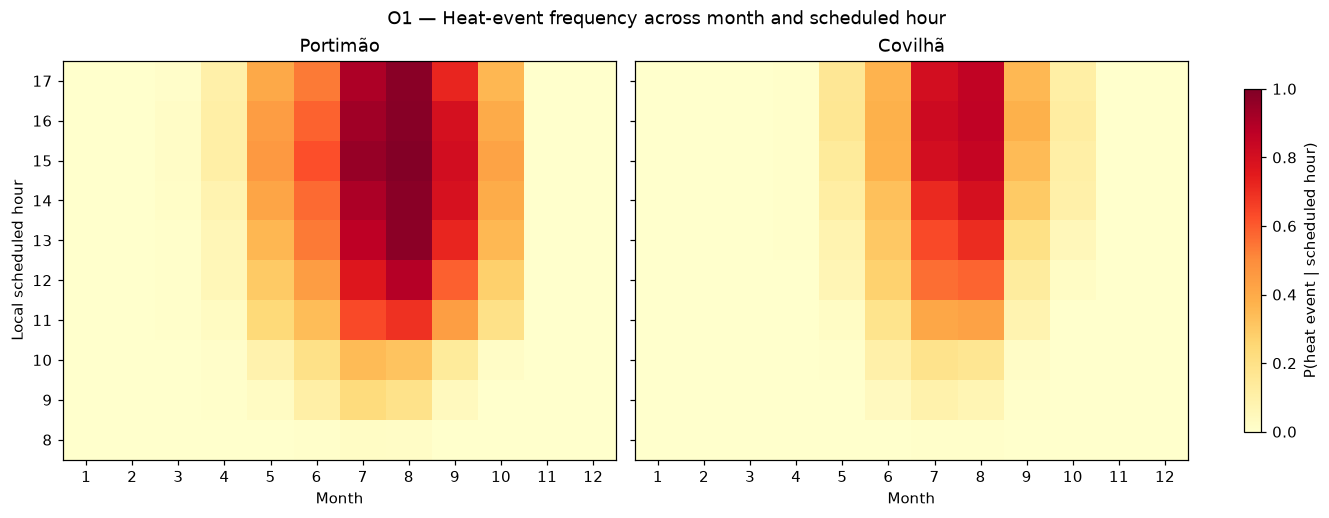

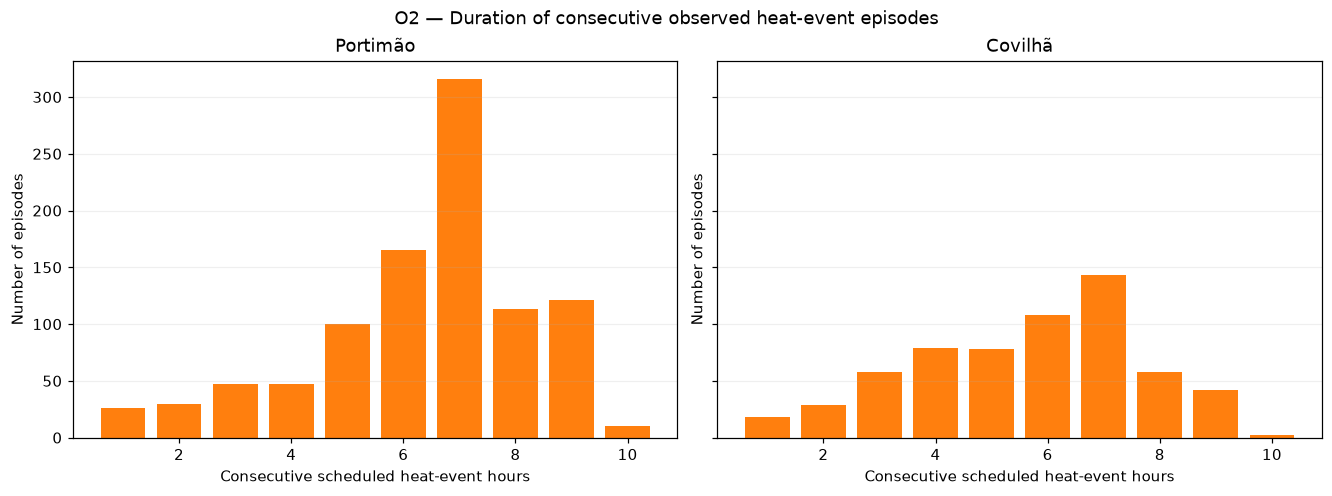

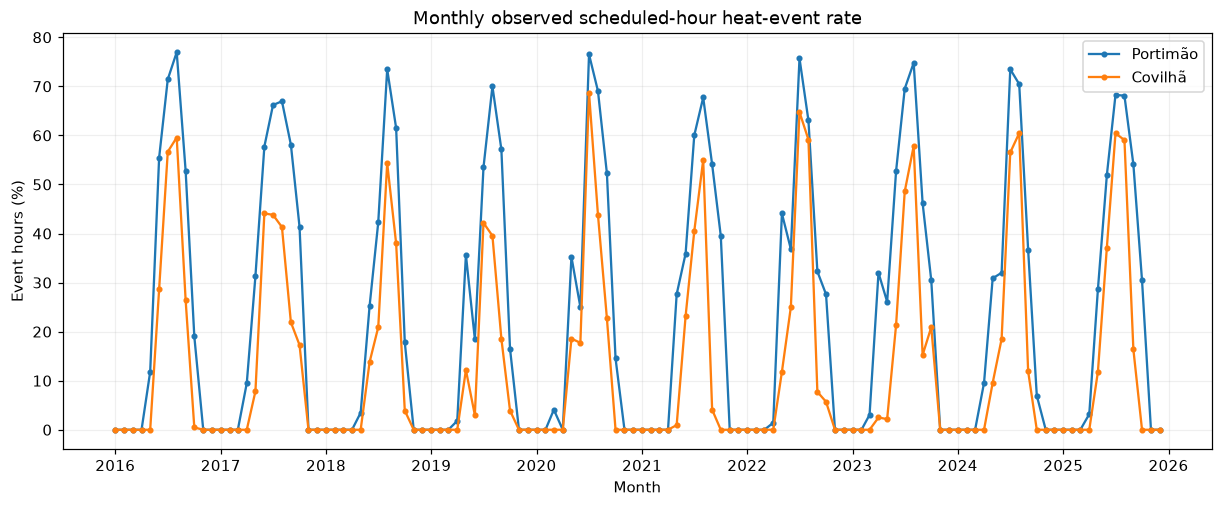

In [9]:
city_profiles = pd.DataFrame([city_a_profile, city_b_profile]).set_index('city')
display(city_profiles.round(2))
city_profiles.to_csv(TABLES_DIR / 'city_comparison.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
images = []
for ax, city in zip(axes, CITIES):
    work = observed_shift(city)
    grid = work.pivot_table(index='local_hour', columns='local_month',
                            values='y_event', aggfunc='mean')
    grid = grid.reindex(index=range(SHIFT_START, SHIFT_END), columns=range(1, 13))
    image = ax.imshow(grid.to_numpy(dtype=float), origin='lower', aspect='auto',
                      vmin=0, vmax=1, cmap='YlOrRd')
    images.append(image)
    ax.set(title=city, xlabel='Month', xticks=range(12),
           xticklabels=list(range(1, 13)), yticks=range(SHIFT_END-SHIFT_START),
           yticklabels=list(range(SHIFT_START, SHIFT_END)))
axes[0].set_ylabel('Local scheduled hour')
fig.colorbar(images[0], ax=axes, shrink=.86, label='P(heat event | scheduled hour)')
fig.suptitle('O1 — Heat-event frequency across month and scheduled hour')
save_figure('O1_heat_exposure_calendar.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, layout='constrained')
for ax, city, episodes in zip(axes, CITIES, (city_a_episodes, city_b_episodes)):
    if len(episodes):
        frequencies = episodes.value_counts().sort_index()
        ax.bar(frequencies.index, frequencies.values, width=.8, color='tab:orange')
    ax.set(title=city, xlabel='Consecutive scheduled heat-event hours',
           ylabel='Number of episodes')
    ax.grid(axis='y', alpha=.2)
fig.suptitle('O2 — Duration of consecutive observed heat-event episodes')
save_figure('O2_heat_episode_duration.png')

fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
for city, monthly in ((CITY_A, city_a_monthly), (CITY_B, city_b_monthly)):
    ax.plot(monthly.index, monthly['event_rate_pct'], marker='.', label=city)
ax.set(title='Monthly observed scheduled-hour heat-event rate',
       ylabel='Event hours (%)', xlabel='Month')
ax.grid(alpha=.2)
ax.legend()
save_figure('city_monthly_event_comparison.png')

## 6. Data Stream Mining experiment
### 6.1 Feature representations and models
We control one feature-related factor at a time. **A (4 features)** uses only the four previous-hour weather observations. **B (11 features)** adds one-hour temperature change, six-hour temperature mean and standard deviation, six-hour humidity mean, past-24-hour rainy-hour count, and cyclical hour-of-day. All rolling features end at *t−1*; the hour-of-day is known in advance. We use the same pooled warm-up preprocessing for each comparison.

The five mandatory incremental learners are implemented with **River**: Gaussian Naive Bayes, online Logistic Regression, Hoeffding Tree, Online Bagging, and Adaptive Random Forest. Each ensemble uses five base estimators for a manageable but genuinely streaming experiment. We store model settings and software versions alongside the metrics.

UnimSafe and UnimPA use the same feature columns and a five-rule budget. Each city and representation gets a fresh learner.

**Tuned Online Bagging (added after hyperparameter search).** The default learners above are kept unchanged. We add one tuned learner: Online Bagging with Hoeffding-tree members, whose settings were chosen by a random search that used **only the 2016–2017 warm-up** (details in the next subsection). Among all tuned models it had the highest 2017 validation Macro-F1 for both representations (A 0.958, B 0.974), so the 2018–2025 evaluation stream played no part in choosing it. The selected configuration differs by representation: A uses 15 members, B uses 20; both use Naive-Bayes-adaptive leaves (`nba`) instead of majority-class leaves.

#### Hyperparameter search behind Tuned Online Bagging
**Method.** We ran a seeded **random search** (`src/tune_hyperparameters.py`) over the value grid below. It is not an exhaustive grid search: the Online Bagging grid alone has 5 × 6 × 4 × 3 × 3 = 1,080 discrete combinations before `delta` is varied. Instead, we sample 120 candidates per model from it (seed 42) and always include the notebook default as candidate 0.

**Protocol: no evaluation-period data is used.**

| Step | Data | Role |
|---|---|---|
| Fit | 2016 work hours, learn only | Train each candidate from a fresh state |
| Validate | 2017 work hours, predict → score → learn | Selection score |
| Report | 2018–2025, the unchanged replay in §6.3 | Never used for any choice |

Median imputation and scaling for the inner loop are refitted on 2016 only, so the 2017 features are also out-of-sample. The selection score is the 2017 Macro-F1 averaged over Portimão and Covilhã. We pick one winner per representation and apply it to both cities.

**What was tested for Online Bagging** (base learner: Hoeffding Tree; ensemble seed 42):

| Parameter | Values tested | Default | Selected A | Selected B |
|---|---|---|---|---|
| `n_models` | 5, 10, 15, 20, 30 | 5 | 15 | 20 |
| `grace_period` | 10, 25, 50, 100, 200, 400 | 50 | 50 | 10 |
| `delta` | log-uniform 1e-9 … 1e-1 | 1e-3 | 6.8e-7 | 7.1e-5 |
| `tau` | 0.01, 0.05, 0.1, 0.2 | 0.1 | 0.2 | 0.1 |
| `leaf_prediction` | `mc`, `nb`, `nba` | `mc` | `nba` | `nba` |
| `split_criterion` | `info_gain`, `gini`, `hellinger` | `info_gain` | `gini` | `info_gain` |

That gives 120 candidates × 2 cities × 2 representations = 480 validation runs.

**Why Online Bagging.** The same search ran for every learner that has hyperparameters:

| Learner | Candidates | What was searched |
|---|---|---|
| Online Logistic Regression | 120 | Optimizer (SGD, Adam, AdaGrad), learning rate 1e-3 … 0.5, L2, intercept rate |
| Hoeffding Tree | 180 | The tree settings above |
| Adaptive Random Forest | 120 | Tree settings, `n_models`, `max_features`, `lambda_value` |
| UnimPA | 180 | Rule-evolution parameters, `max_rules` 2 … 20 |
| UnimSafe | 180 | Rule-evolution parameters, `max_rules` 2 … 20 |

Gaussian Naive Bayes has no hyperparameters. In total the search covered 901 candidates and 3,604 validation runs. Online Bagging reached the highest 2017 Macro-F1 in **both** representations, so it is the learner we add. The cell below rebuilds this evidence from the saved trials.

In [10]:
# Search evidence from the saved trials (2017 validation scores only; no 2018-2025 data).
trials_file = RESULTS_DIR / 'tuning' / 'validation_trials.csv'
if not trials_file.exists():
    print('Run `python src/tune_hyperparameters.py` to create', trials_file)
else:
    trials = pd.read_csv(trials_file)
    # Selection score: mean 2017 Macro-F1 over the two cities.
    per_candidate = (trials.groupby(['model', 'representation', 'candidate', 'params'],
                                    as_index=False)['macro_f1'].mean())
    search_summary = per_candidate.groupby(['model', 'representation']).agg(
        candidates=('candidate', 'nunique'),
        default_macro_f1=('macro_f1', lambda s: s[per_candidate.loc[s.index, 'candidate'] == 0].iloc[0]),
        best_macro_f1=('macro_f1', 'max'),
    )
    print('2017 validation Macro-F1, default vs best candidate, per learner:')
    display(search_summary.unstack('representation').round(4))

    bagging = per_candidate.loc[per_candidate['model'] == 'Online Bagging'].reset_index(drop=True)
    bagging = bagging.join(pd.json_normalize(bagging['params'].map(json.loads)))
    bagging = bagging.drop(columns=['model', 'params'])
    for factor in ('leaf_prediction', 'n_models'):
        print(f'Online Bagging: 2017 Macro-F1 by {factor} (mean and best over sampled candidates):')
        display(bagging.pivot_table(index=factor, columns='representation', values='macro_f1',
                                    aggfunc=['mean', 'max']).round(4))
    print('Online Bagging: five best candidates per representation:')
    display(bagging.sort_values('macro_f1', ascending=False).groupby('representation').head(5)
            .round({'macro_f1': 4}).reset_index(drop=True))

2017 validation Macro-F1, default vs best candidate, per learner:


candidates      default_macro_f1          \
representation                      A    B                A       B   
model                                                                 
Adaptive Random Forest            120  120           0.9422  0.9477   
Gaussian Naive Bayes                1    1           0.8465  0.8395   
Hoeffding Tree                    180  180           0.9373  0.9372   
Online Bagging                    120  120           0.9465  0.9449   
Online Logistic Regression        120  120           0.9413  0.9405   
UnimPA                            180  180           0.9003  0.8919   
UnimSafe                          180  180           0.6115  0.6623   

                           best_macro_f1          
representation                         A       B  
model                                             
Adaptive Random Forest            0.9541  0.9601  
Gaussian Naive Bayes              0.8465  0.8395  
Hoeffding Tree                    0.9566  0.9653  
Online Bagging                    0.9581  0.9738  
Online Logistic Regression        0.9571  0.9573  
UnimPA                            0.9062  0.8922  
UnimSafe                          0.7869  0.7871

Online Bagging: 2017 Macro-F1 by leaf_prediction (mean and best over sampled candidates):


mean             max        
representation        A       B       A       B
leaf_prediction                                
mc               0.9493  0.9483  0.9559  0.9716
nb               0.9041  0.5030  0.9534  0.9531
nba              0.9538  0.9614  0.9581  0.9738

Online Bagging: 2017 Macro-F1 by n_models (mean and best over sampled candidates):


mean             max        
representation       A       B       A       B
n_models                                      
5               0.9295  0.7729  0.9567  0.9676
10              0.9276  0.7491  0.9576  0.9702
15              0.9383  0.8237  0.9581  0.9736
20              0.9374  0.8131  0.9577  0.9738
30              0.9484  0.8722  0.9581  0.9723

Online Bagging: five best candidates per representation:


,representation,candidate,macro_f1,n_models,grace_period,delta,tau,leaf_prediction,split_criterion
0,B,100,0.9738,20,10,7.056941e-05,0.10,nba,info_gain
1,B,93,0.9736,15,50,6.798390e-07,0.20,nba,gini
2,B,37,0.9723,30,50,3.706483e-08,0.20,nba,info_gain
3,B,1,0.9716,15,25,9.481269e-02,0.20,mc,info_gain
4,B,110,0.9710,30,200,5.278110e-09,0.20,nba,info_gain
5,A,93,0.9581,15,50,6.798390e-07,0.20,nba,gini
6,A,110,0.9581,30,200,5.278110e-09,0.20,nba,info_gain
7,A,79,0.9577,20,100,3.181408e-08,0.20,nba,gini
8,A,76,0.9576,10,100,3.606629e-05,0.01,nba,info_gain
9,A,18,0.9574,10,25,2.771623e-03,0.01,nba,gini


**Reading the search.**

- **Leaf prediction decides the outcome.** With plain Naive-Bayes leaves (`nb`), representation B collapses: the mean 2017 Macro-F1 is about 0.50, meaning the models predict a single class. The adaptive variant `nba` is the most robust choice, and 9 of the 10 best candidates use it.
- **More ensemble members help on average,** but the best scores level off from about 15 members.
- **The winner sits on a plateau, not a sharp peak.** The five best candidates are within about 0.001 (A) and 0.003 (B) of each other. Differences that small are within validation noise.
- **The 2017 gain overstates the long-run gain.** On 2017, tuning improved Online Bagging by about +0.012 (A) and +0.029 (B). On 2018–2025 the improvement is smaller (§6.3), which is expected after selecting the best of 120 candidates on a single year.

In [11]:
try:
    from river import ensemble, forest, linear_model, naive_bayes, optim, tree
except ImportError as error:
    raise ImportError('River is required for all five official models. '
                      'Install requirements.txt in this Jupyter kernel, restart, and Run All.') from error

if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from ENF_UnimNeuron_PA import EvolvingNeuroFuzzyUnimPA
from ENF_UnimNeuron_Safe import EvolvingNeuroFuzzyUnimSafe

FUZZY = {'UnimPA': EvolvingNeuroFuzzyUnimPA, 'UnimSafe': EvolvingNeuroFuzzyUnimSafe}

class FuzzyStreamModel:
    """Map named stream features to the supplied model's fixed column order."""
    def __init__(self, name, columns):
        self.columns = columns
        self.learner = FUZZY[name](n_features=len(columns), n_classes=2,
                                   max_rules=5, random_state=RANDOM_SEED)

    def inputs(self, x):
        return np.array([[x[key] for key in self.columns]], dtype=float)

    def predict_one(self, x):
        return int(self.learner.predict(self.inputs(x))[0])

    def learn_one(self, x, y):
        self.learner.partial_fit(self.inputs(x), np.array([y]))

# Selected on the 2016-2017 warm-up only by src/tune_hyperparameters.py
# (results/tuning/best_parameters.json); one configuration per representation.
TUNED_BAGGING = {
    'A': {'n_models': 15, 'grace_period': 50, 'delta': 6.798389918397393e-07,
          'tau': 0.2, 'leaf_prediction': 'nba', 'split_criterion': 'gini'},
    'B': {'n_models': 20, 'grace_period': 10, 'delta': 7.056941046962843e-05,
          'tau': 0.1, 'leaf_prediction': 'nba', 'split_criterion': 'info_gain'},
}

MODEL_NAMES = [
    'Gaussian Naive Bayes', 'Online Logistic Regression',
    'Hoeffding Tree', 'Online Bagging', 'Adaptive Random Forest', *FUZZY,
    'Tuned Online Bagging',
]
MODEL_PARAMETERS = {
    'Gaussian Naive Bayes': {'model': 'GaussianNB', 'settings': 'River defaults'},
    'Online Logistic Regression': {'model': 'LogisticRegression', 'sgd_lr': 0.05},
    'Hoeffding Tree': {'model': 'HoeffdingTreeClassifier', 'grace_period': 50,
                       'delta': .001, 'tau': .1, 'leaf_prediction': 'mc'},
    'Online Bagging': {'model': 'BaggingClassifier', 'n_models': ENSEMBLE_SIZE,
                       'base_model': 'HoeffdingTreeClassifier', 'seed': RANDOM_SEED},
    'Adaptive Random Forest': {'model': 'ARFClassifier', 'n_models': ENSEMBLE_SIZE,
                               'max_features': 'sqrt', 'lambda_value': 6,
                               'grace_period': 50, 'delta': .001,
                               'tau': .1, 'leaf_prediction': 'mc', 'seed': RANDOM_SEED},
}


MODEL_PARAMETERS['Tuned Online Bagging'] = {
    'model': 'BaggingClassifier', 'base_model': 'HoeffdingTreeClassifier',
    'seed': RANDOM_SEED, 'selection': 'random search on 2016-2017 warm-up only',
    'representation_A': TUNED_BAGGING['A'], 'representation_B': TUNED_BAGGING['B'],
}

for name, cls in FUZZY.items():
    MODEL_PARAMETERS[name] = {'model': cls.__name__, 'max_rules': 5, 'n_classes': 2,
                              'random_state': RANDOM_SEED, 'other_settings': 'source defaults'}

def make_tree():
    return tree.HoeffdingTreeClassifier(grace_period=50, delta=.001,
                                        tau=.1, leaf_prediction='mc')


def new_model(name, columns=REP_A):
    """Return a fresh learner for each city × representation × model run."""
    if name in FUZZY:
        return FuzzyStreamModel(name, columns)
    if name == 'Gaussian Naive Bayes':
        return naive_bayes.GaussianNB()
    if name == 'Online Logistic Regression':
        return linear_model.LogisticRegression(optimizer=optim.SGD(.05))
    if name == 'Hoeffding Tree':
        return make_tree()
    if name == 'Online Bagging':
        return ensemble.BaggingClassifier(model=make_tree(),
                                          n_models=ENSEMBLE_SIZE, seed=RANDOM_SEED)
    if name == 'Tuned Online Bagging':
        params = dict(TUNED_BAGGING['B' if list(columns) == REP_B else 'A'])
        n_models = params.pop('n_models')
        return ensemble.BaggingClassifier(model=tree.HoeffdingTreeClassifier(**params),
                                          n_models=n_models, seed=RANDOM_SEED)
    if name == 'Adaptive Random Forest':
        return forest.ARFClassifier(n_models=ENSEMBLE_SIZE, max_features='sqrt',
                                    lambda_value=6, grace_period=50, delta=.001,
                                    tau=.1, leaf_prediction='mc', seed=RANDOM_SEED)
    raise KeyError(name)


for model_name in MODEL_NAMES:
    candidate_model = new_model(model_name)
    assert hasattr(candidate_model, 'predict_one') and hasattr(candidate_model, 'learn_one')
model_table = pd.DataFrame([
    {
        'Model': name,
        'Configuration': ', '.join(
            f'{key}={value}'
            for key, value in parameters.items()
        )
    }
    for name, parameters in MODEL_PARAMETERS.items()
])

display(model_table)
print(f'All {len(MODEL_NAMES)} learners initialized; River', installed_version('river'))

,Model,Configuration
0,Gaussian Naive Bayes,"model=GaussianNB, settings=River defaults"
1,Online Logistic Regression,"model=LogisticRegression, sgd_lr=0.05"
2,Hoeffding Tree,"model=HoeffdingTreeClassifier, grace_period=50..."
3,Online Bagging,"model=BaggingClassifier, n_models=5, base_mode..."
4,Adaptive Random Forest,"model=ARFClassifier, n_models=5, max_features=..."
5,Tuned Online Bagging,"model=BaggingClassifier, base_model=HoeffdingT..."
6,UnimPA,"model=EvolvingNeuroFuzzyUnimPA, max_rules=5, n..."
7,UnimSafe,"model=EvolvingNeuroFuzzyUnimSafe, max_rules=5,..."


All 8 learners initialized; River 0.24.2


### 6.2 Evaluation metrics and sequential replay
We score Accuracy, Macro-F1, positive-event Precision and Recall, and the **TN / FP / FN / TP** confusion matrix. The positive label is always 1. Where no positive prediction or event is available, the corresponding metric uses zero division → 0. We also time prediction and update steps **separately** in milliseconds per scored event. Checkpoint metrics show whether performance changes over time.

During warm-up the learner receives labeled 2016–2017 events without scoring them. During evaluation (2018–2025), we call `predict_one`, update our recorded metrics, and **only then** call `learn_one` with the same event's label.

In [12]:
def confusion_metrics(tn, fp, fn, tp):
    n = tn + fp + fn + tp
    precision_1 = tp / (tp + fp) if tp + fp else 0.0
    recall_1 = tp / (tp + fn) if tp + fn else 0.0
    precision_0 = tn / (tn + fn) if tn + fn else 0.0
    recall_0 = tn / (tn + fp) if tn + fp else 0.0
    f1_1 = 2 * precision_1 * recall_1 / (precision_1 + recall_1) if precision_1 + recall_1 else 0.0
    f1_0 = 2 * precision_0 * recall_0 / (precision_0 + recall_0) if precision_0 + recall_0 else 0.0
    return {
        'n_evaluated': n, 'accuracy': (tn + tp) / n if n else 0.0,
        'macro_f1': (f1_0 + f1_1) / 2,
        'precision_event': precision_1, 'recall_event': recall_1,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }


class OnlineScores:
    def __init__(self, window=ROLLING_SCORE_WINDOW):
        self.counts = np.zeros((2, 2), dtype=int)  # [actual, predicted]
        self.recent = deque(maxlen=window)

    def add(self, actual, predicted):
        self.counts[int(actual), int(predicted)] += 1
        self.recent.append((int(actual), int(predicted)))

    def snapshot(self):
        tn, fp, fn, tp = self.counts.ravel().tolist()
        report = confusion_metrics(tn, fp, fn, tp)
        recent_counts = np.zeros((2, 2), dtype=int)
        for actual, predicted in self.recent:
            recent_counts[actual, predicted] += 1
        report['rolling_macro_f1'] = confusion_metrics(*recent_counts.ravel())['macro_f1']
        return report


assert confusion_metrics(3, 1, 2, 4)['accuracy'] == .7
assert confusion_metrics(3, 1, 2, 4)['FN'] == 2
print('PASS — binary confusion-matrix and metric unit tests.')


def replay(city, representation, model_name):
    """Warm up on 2016–2017; predict → evaluate → learn during 2018–2025."""
    model = new_model(model_name, REP_A if representation == "A" else REP_B)
    X = scaled_inputs[(city, representation)]
    y = stream_full[city].loc[model_times, 'y_event'].astype(int)

    for timestamp in warm_times:
        model.learn_one(X.loc[timestamp].to_dict(), int(y.loc[timestamp]))

    identity = dict(city=city, representation=representation, model=model_name)
    if model_name in FUZZY:
        rule_history.append(dict(**identity, n_evaluated=0, rules=model.learner.n_rules_))
    scores = OnlineScores()
    prediction_ns = update_ns = missing_predictions = 0
    checkpoints = []
    for number, timestamp in enumerate(eval_times, start=1):
        features = X.loc[timestamp].to_dict()
        actual = int(y.loc[timestamp])

        before = time.perf_counter_ns()
        raw_prediction = model.predict_one(features)
        prediction_ns += time.perf_counter_ns() - before
        if raw_prediction is None:
            missing_predictions += 1
        predicted = 0 if raw_prediction is None else int(raw_prediction)
        scores.add(actual, predicted)  # EVALUATE — the label has not reached the learner.

        before = time.perf_counter_ns()
        model.learn_one(features, actual)  # LEARN only after evaluation.
        update_ns += time.perf_counter_ns() - before

        if number == 1 or number % CHECKPOINT_EVERY == 0 or number == len(eval_times):
            if model_name in FUZZY:
                rule_history.append(dict(**identity, n_evaluated=number, rules=model.learner.n_rules_))
            checkpoints.append({
                'city': city, 'representation': representation,
                'model': model_name, 'timestamp_utc': str(timestamp),
                **scores.snapshot(),
            })

    report = scores.snapshot()
    assert report['n_evaluated'] == len(eval_times)
    report.update({
        'city': city, 'representation': representation, 'model': model_name,
        'prediction_ms_per_event': prediction_ns / 1e6 / len(eval_times),
        'update_ms_per_event': update_ns / 1e6 / len(eval_times),
        'none_predictions': missing_predictions,
        'warmup_events': len(warm_times),
        'evaluation_start_utc': str(eval_times.min()),
        'evaluation_end_utc': str(eval_times.max()),
        'target_threshold_c': HOT_THRESHOLD_C,
    })
    report.pop('rolling_macro_f1')  # Save time-varying values in checkpoints instead.
    if model_name in FUZZY:
        learner = model.learner
        unit, size = 'rules', learner.n_rules_
        config = scaler_config[representation]
        for i, rule in enumerate(learner.rules):
            center = rule.center * np.array(config['scales']) + config['means']
            row = dict(**identity, rule=i + 1, support=rule.support, sigma_z=rule.sigma,
                       prediction_at_center=int(learner.predict(rule.center[None, :])[0]))
            for feature, value, weight in zip(model.columns, center, rule.w):
                row['center_' + feature] = value
                row['weight_' + feature] = weight
            if model_name == 'UnimPA':
                row['pa_event_minus_non_event'] = learner.W[i+1, 1] - learner.W[i+1, 0]
                row['pa_bias_difference'] = learner.W[0, 1] - learner.W[0, 0]
            else:
                row['rule_event_share'] = rule.class_probs()[1]
            rule_rows.append(row)
    elif model_name == 'Hoeffding Tree':
        unit, size = 'tree nodes', model.n_nodes
    elif model_name in ('Online Bagging', 'Tuned Online Bagging', 'Adaptive Random Forest'):
        unit, size = 'active ensemble tree nodes', sum((member.n_nodes or 0) for member in model.models)
    elif model_name == 'Online Logistic Regression':
        unit, size = 'coefficients incl. intercept', len(model.weights) + 1
    else:
        unit, size = 'class-feature Gaussians', sum(len(distributions) for distributions in model.gaussians.values())
    complexity_rows.append(dict(**identity, unit=unit, final_size=size))
    return report, checkpoints

PASS — binary confusion-matrix and metric unit tests.


### 6.3 Run the complete controlled experiment
We run **2 cities × 2 representations × 8 models = 32 experiments** (the seven default learners plus Tuned Online Bagging). Results are generated from fresh model states without hyperparameter selection on the evaluation period; the tuned configuration was fixed beforehand from the warm-up. We save `results/metrics.csv`, `results/configurations.csv`, checkpoint histories and full confusion counts for direct auditing. Ensemble runs may take several minutes.

In [13]:
rule_history, rule_rows, complexity_rows = [], [], []
metrics_rows, checkpoint_rows, configuration_rows = [], [], []
experiment_start = time.perf_counter()
for city in CITIES:
    for representation in ('A', 'B'):
        for model_name in MODEL_NAMES:
            result, checkpoints = replay(city, representation, model_name)
            metrics_rows.append(result)
            checkpoint_rows.extend(checkpoints)
            configuration_rows.append({
                'assignment': PA_CODE, 'city': city,
                'representation': representation, 'model': model_name,
                'features': json.dumps(REP_A if representation == 'A' else REP_B),
                'parameters': json.dumps(MODEL_PARAMETERS[model_name]),
                'warmup_end_utc': str(WARMUP_END_UTC),
                'evaluation_first_utc': str(eval_times.min()),
                'evaluation_last_utc': str(eval_times.max()),
                'target_threshold_c': HOT_THRESHOLD_C,
                'random_seed': RANDOM_SEED,
                'river_version': installed_version('river'),
            })
            print(f'Completed {city:9s} | {representation} | {model_name}')

metrics = pd.DataFrame(metrics_rows)
checkpoints = pd.DataFrame(checkpoint_rows)
configurations = pd.DataFrame(configuration_rows)
N_EXPERIMENTS = len(CITIES) * 2 * len(MODEL_NAMES)
assert len(metrics) == N_EXPERIMENTS
assert metrics['n_evaluated'].eq(len(eval_times)).all()
assert (metrics[['TN', 'FP', 'FN', 'TP']].sum(axis=1) == len(eval_times)).all()
metrics.to_csv(RESULTS_DIR / 'metrics.csv', index=False)
configurations.to_csv(RESULTS_DIR / 'configurations.csv', index=False)
checkpoints.to_csv(RESULTS_DIR / 'checkpoints.csv', index=False)
metrics[['city', 'representation', 'model', 'TN', 'FP', 'FN', 'TP']].to_csv(
    RESULTS_DIR / 'confusion_matrices.csv', index=False)
print(f'Completed {N_EXPERIMENTS} controlled experiments in {(time.perf_counter()-experiment_start)/60:.1f} min.')
display(metrics[['city', 'representation', 'model', 'accuracy', 'macro_f1',
                 'precision_event', 'recall_event', 'prediction_ms_per_event',
                 'update_ms_per_event']].round(4))

Completed Portimão  | A | Gaussian Naive Bayes


Completed Portimão  | A | Online Logistic Regression


Completed Portimão  | A | Hoeffding Tree


Completed Portimão  | A | Online Bagging


Completed Portimão  | A | Adaptive Random Forest


Completed Portimão  | A | UnimPA


... (23 outputs left out)

Completed Covilhã   | B | UnimPA


Completed Covilhã   | B | UnimSafe


Completed Covilhã   | B | Tuned Online Bagging
Completed 32 controlled experiments in 2.1 min.


,city,representation,model,accuracy,macro_f1,precision_event,recall_event,prediction_ms_per_event,update_ms_per_event
0,Portimão,A,Gaussian Naive Bayes,0.8919,0.8664,0.6878,0.9794,0.0506,0.0022
1,Portimão,A,Online Logistic Regression,0.9632,0.9483,0.9258,0.9151,0.0014,0.0042
2,Portimão,A,Hoeffding Tree,0.9648,0.9500,0.9432,0.9032,0.0052,0.0066
3,Portimão,A,Online Bagging,0.9651,0.9500,0.9520,0.8950,0.0215,0.0296
4,Portimão,A,Adaptive Random Forest,0.9602,0.9437,0.9259,0.9009,0.0219,0.0619
5,Portimão,A,UnimPA,0.9461,0.9235,0.8995,0.8649,0.0532,0.1140
6,Portimão,A,UnimSafe,0.8290,0.7582,0.6360,0.6187,0.0600,0.0715
7,Portimão,A,Tuned Online Bagging,0.9670,0.9530,0.9507,0.9053,0.0674,0.1804
8,Portimão,B,Gaussian Naive Bayes,0.8866,0.8593,0.6822,0.9590,0.0560,0.0039
9,Portimão,B,Online Logistic Regression,0.9686,0.9561,0.9321,0.9331,0.0016,0.0057


## 7. Results — evidence tables and figures
We export the mandatory model metrics and confusion matrices for both feature representations and both cities. Additional controlled comparisons show **B − A** in Macro-F1 and event Recall, while cost-versus-detection plots retain the distinction between predictive value and computational expense.

,city,accuracy,macro_f1,recall_event,FN
0,Portimão,0.7675,0.4342,0.0,4855
1,Covilhã,0.8705,0.4654,0.0,2703


,city,model,accuracy_B_minus_A,macro_f1_B_minus_A,recall_event_B_minus_A
0,Covilhã,Adaptive Random Forest,-0.0011,-0.0026,-0.0059
1,Covilhã,Gaussian Naive Bayes,-0.0174,-0.0270,-0.0067
2,Covilhã,Hoeffding Tree,0.0032,0.0070,0.0107
3,Covilhã,Online Bagging,0.0057,0.0133,0.0400
4,Covilhã,Online Logistic Regression,0.0006,0.0014,0.0067
5,Covilhã,Tuned Online Bagging,0.0077,0.0174,0.0403
6,Covilhã,UnimPA,-0.0162,-0.0340,-0.0303
7,Covilhã,UnimSafe,0.0069,0.1381,0.2642
8,Portimão,Adaptive Random Forest,-0.0007,-0.0012,-0.0056
9,Portimão,Gaussian Naive Bayes,-0.0053,-0.0072,-0.0204


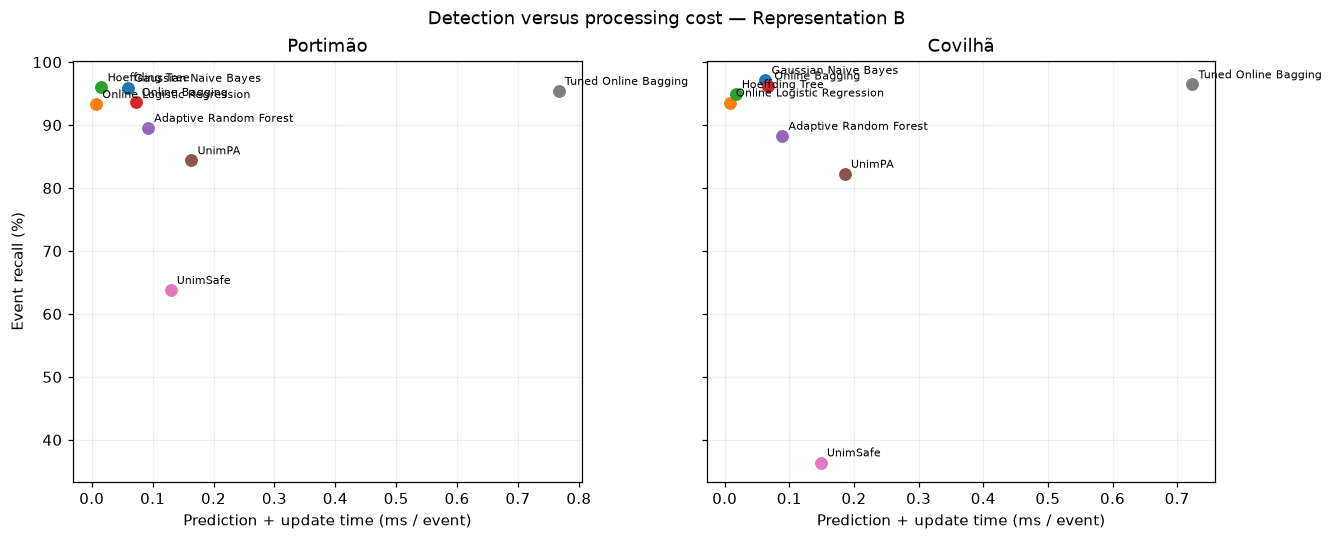

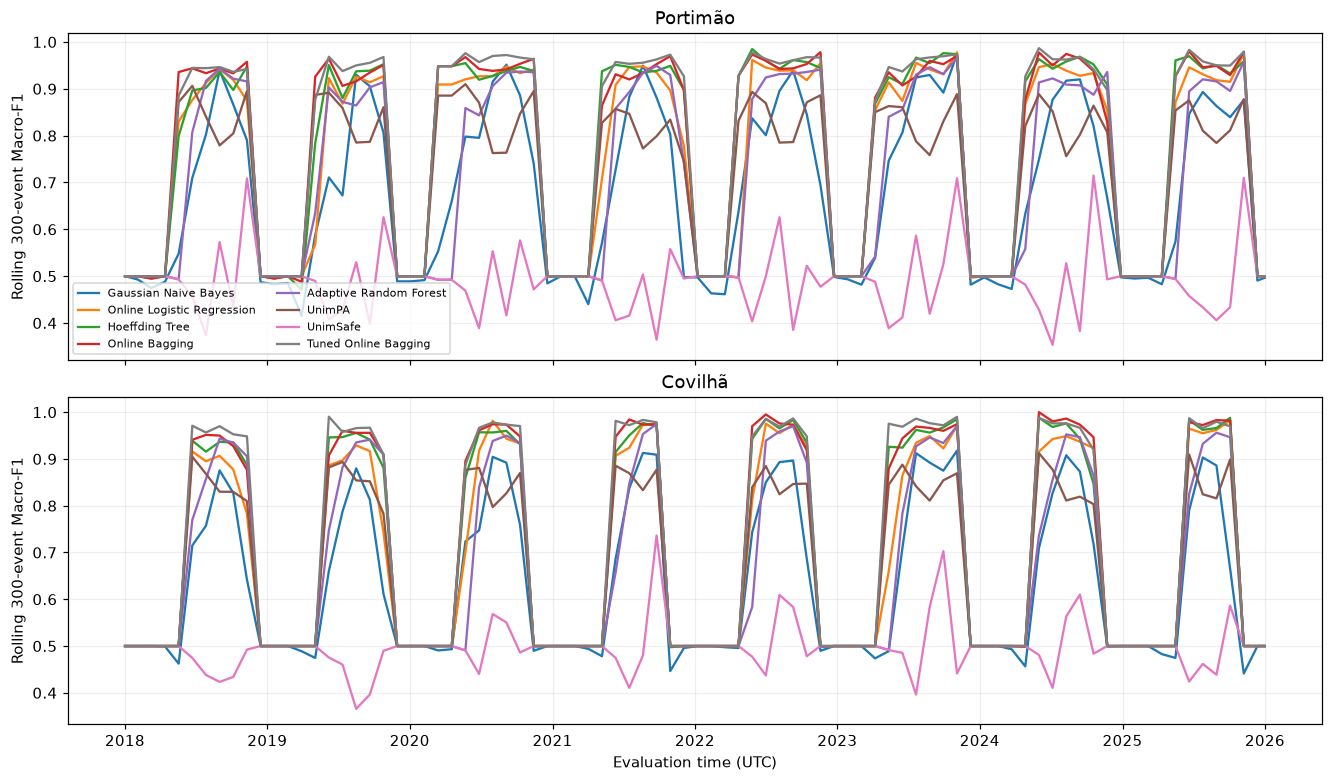

In [14]:
# The identical baseline (always predict no heat event) contextualises class imbalance.
baseline_rows = []
for city in CITIES:
    actual = stream_full[city].loc[eval_times, 'y_event'].astype(int)
    baseline_rows.append({
        'city': city, 'baseline': 'Always predict no event',
        **confusion_metrics(int((actual == 0).sum()), 0, int((actual == 1).sum()), 0),
    })
baseline = pd.DataFrame(baseline_rows)
baseline.to_csv(TABLES_DIR / 'always_negative_baseline.csv', index=False)
display(baseline[['city', 'accuracy', 'macro_f1', 'recall_event', 'FN']].round(4))

wide = metrics.pivot(index=['city', 'model'], columns='representation',
                     values=['macro_f1', 'recall_event', 'accuracy'])
representation_delta = pd.DataFrame({
    f'{score}_B_minus_A': wide[(score, 'B')] - wide[(score, 'A')]
    for score in ('accuracy', 'macro_f1', 'recall_event')
}).reset_index()
representation_delta.to_csv(TABLES_DIR / 'representation_B_minus_A.csv', index=False)
display(representation_delta.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout='constrained')
for ax, city in zip(axes, CITIES):
    subset = metrics.loc[(metrics['city'] == city) & (metrics['representation'] == 'B')]
    total_cost = subset['prediction_ms_per_event'] + subset['update_ms_per_event']
    for (_, result), x_value in zip(subset.iterrows(), total_cost):
        ax.scatter(x_value, result['recall_event'] * 100, s=55)
        ax.annotate(result['model'], (x_value, result['recall_event'] * 100),
                    xytext=(4, 4), textcoords='offset points', fontsize=7)
    ax.set(title=city, xlabel='Prediction + update time (ms / event)')
    ax.grid(alpha=.2)
axes[0].set_ylabel('Event recall (%)')
fig.suptitle('Detection versus processing cost — Representation B')
save_figure('model_recall_vs_cost.png')

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
for ax, city in zip(axes, CITIES):
    for model_name in MODEL_NAMES:
        subset = checkpoints.loc[(checkpoints['city'] == city) &
                                 (checkpoints['representation'] == 'B') &
                                 (checkpoints['model'] == model_name)]
        ax.plot(pd.to_datetime(subset['timestamp_utc'], utc=True),
                subset['rolling_macro_f1'], label=model_name)
    ax.set(title=city, ylabel=f'Rolling {ROLLING_SCORE_WINDOW}-event Macro-F1')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=7, ncol=2)
axes[1].set_xlabel('Evaluation time (UTC)')
save_figure('model_rolling_macro_f1.png')

### 7.3 Model complexity and fuzzy rule structure
Compare final sizes within each model family. Fuzzy snapshots track the number of rules after warm-up and at each score checkpoint. Final rule centres are in the original feature units. Support counts premise assignments. A Safe rule reports its event share and a PA rule its signed contribution per unit of normalized activation. Prediction at the centre uses the entire model. Rule numbers identify final slots only.

city                                                    Portimão      Covilhã  \
representation                                                 A    B       A   
model                      unit                                                 
Adaptive Random Forest     active ensemble tree nodes         65   59      27   
Gaussian Naive Bayes       class-feature Gaussians             8   22       8   
Hoeffding Tree             tree nodes                         39   33      21   
Online Bagging             active ensemble tree nodes        201  179     109   
Online Logistic Regression coefficients incl. intercept        5   12       5   
Tuned Online Bagging       active ensemble tree nodes        921  706     537   
UnimPA                     rules                               5    5       5   
UnimSafe                   rules                               5    5       5   

city                                                          
representation                                             B  
model                      unit                               
Adaptive Random Forest     active ensemble tree nodes     29  
Gaussian Naive Bayes       class-feature Gaussians        22  
Hoeffding Tree             tree nodes                     19  
Online Bagging             active ensemble tree nodes     99  
Online Logistic Regression coefficients incl. intercept   12  
Tuned Online Bagging       active ensemble tree nodes    486  
UnimPA                     rules                           5  
UnimSafe                   rules                           5

,city,representation,model,rule,support,sigma_z,prediction_at_center,center_lag1_temperature_2m,weight_lag1_temperature_2m,center_lag1_relative_humidity_2m,...,center_temperature_std_6h,weight_temperature_std_6h,center_humidity_mean_6h,weight_humidity_mean_6h,center_rainy_hours_24h,weight_rainy_hours_24h,center_shift_hour_sin,weight_shift_hour_sin,center_shift_hour_cos,weight_shift_hour_cos
23,Covilhã,A,UnimPA,4,7766,1.507,0,22.980,1.000,41.485,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
28,Covilhã,A,UnimSafe,4,7766,1.507,0,22.980,0.250,41.485,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,Covilhã,B,UnimPA,3,10868,2.434,0,12.457,1.000,72.536,...,1.370,1.000,79.275,1.000,1.157,1.000,0.349,1.000,-0.806,1.000
37,Covilhã,B,UnimSafe,3,10868,2.434,0,12.457,0.091,72.536,...,1.370,0.091,79.275,0.091,1.157,0.091,0.349,0.091,-0.806,0.091
0,Portimão,A,UnimPA,1,4847,1.372,0,16.001,1.000,77.880,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Portimão,A,UnimSafe,1,4847,1.372,0,16.001,0.250,77.880,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,Portimão,B,UnimPA,1,1020,2.260,0,19.778,1.000,61.861,...,2.138,1.000,74.015,1.000,1.125,1.000,-0.297,1.000,-0.896,1.000
15,Portimão,B,UnimSafe,1,1020,2.260,0,19.778,0.091,61.861,...,2.138,0.091,74.015,0.091,1.125,0.091,-0.297,0.091,-0.896,0.091


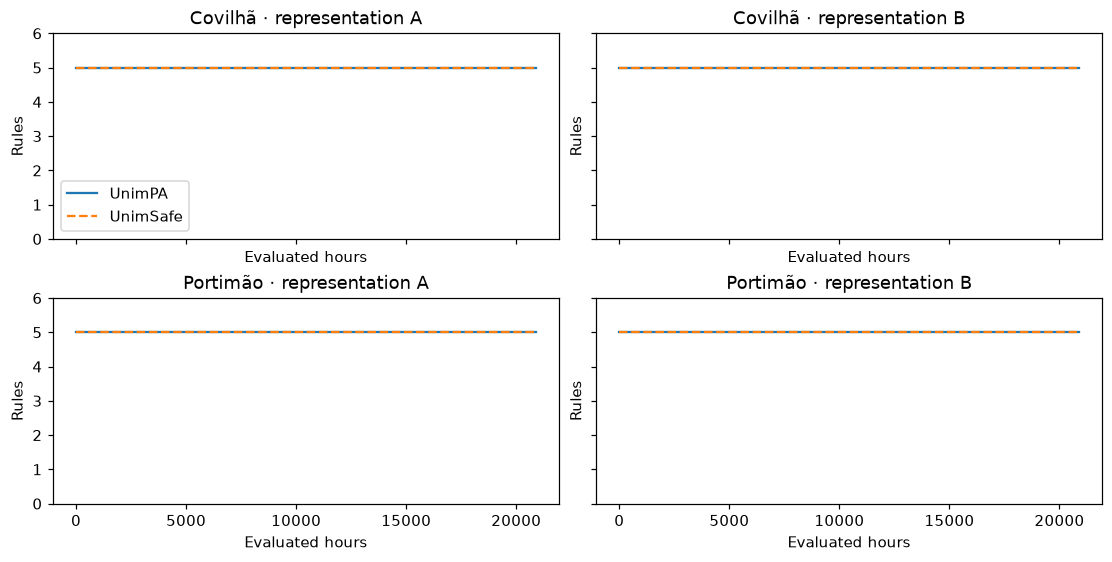

In [15]:
complexity = pd.DataFrame(complexity_rows)
history = pd.DataFrame(rule_history)
rules = pd.DataFrame(rule_rows)
assert len(complexity) == len(metrics) and history.rules.between(1, 5).all()
for filename, frame in [('model_complexity', complexity), ('rule_history', history), ('final_rules', rules)]:
    frame.to_csv(TABLES_DIR / (filename + '.csv'), index=False)
display(complexity.pivot(index=['model', 'unit'], columns=['city', 'representation'], values='final_size'))
# Largest-support final premise for each city, representation and fuzzy learner.
examples = rules.loc[rules.groupby(['city', 'representation', 'model']).support.idxmax()]
display(examples.dropna(axis=1, how='all').round(3))
fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10, 5), layout='constrained')
for ax, ((city, rep), subset) in zip(axes.flat, history.groupby(['city', 'representation'])):
    for name, group in subset.groupby('model'):
        ax.step(group.n_evaluated, group.rules, where='post', label=name,
                linestyle='--' if name == 'UnimSafe' else '-')
    ax.set(title=f'{city} · representation {rep}', xlabel='Evaluated hours', ylabel='Rules', ylim=(0, 6))
axes.flat[0].legend()
save_figure('fuzzy_rule_counts.png')

**Reading the rule results.** Both variants reached the five-rule cap before evaluation and had five rules at every checkpoint. In Portimão with representation A, their warmest final premise was centred on 25.92 °C and 43.2% humidity. UnimPA gave that slot a positive event-score contribution (+22.59 per unit of normalized activation), while UnimSafe’s local event share was 0.004. Both models predicted a non-event at this centre when all five rules voted. These December snapshots describe the final model state. The full replay gives a different view of the models: in Covilhã with A, UnimPA detected 85.3% of hot hours and UnimSafe detected 10.0%.